In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Clean styling without future warnings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.autolayout'] = True

# Load dataset
df = pd.read_csv('Dataset .csv')
print(f"Data successfully loaded: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head(2)


Data successfully loaded: 9551 rows, 21 columns.


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591


Rating Range Distribution:
Rating_Range
0.0 - 1.9    2151
2.0 - 2.9    1430
3.0 - 3.9    4590
4.0 - 4.9    1380
5.0             0
Name: count, dtype: int64

1. Most common rating range: 3.0 - 3.9 (4590 restaurants)
2. Overall average number of votes per restaurant: 156.91


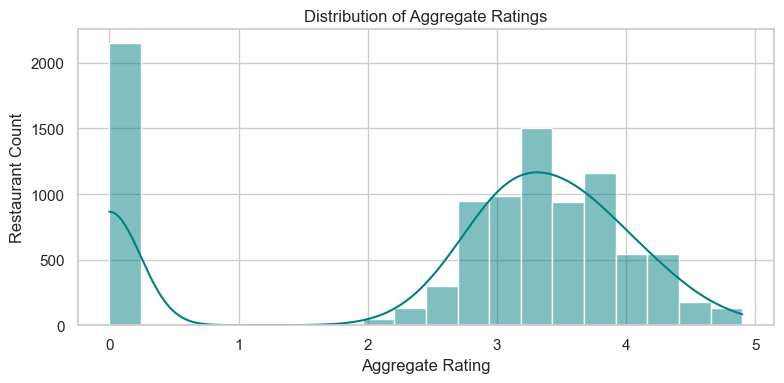

In [2]:
# Task 1: Ratings Distribution and Average Votes
# Bin aggregate ratings into ranges
bins = [0, 1.9, 2.9, 3.9, 4.9, 5.0]
labels = ['0.0 - 1.9', '2.0 - 2.9', '3.0 - 3.9', '4.0 - 4.9', '5.0']
df['Rating_Range'] = pd.cut(df['Aggregate rating'], bins=bins, labels=labels, include_lowest=True)

rating_distribution = df['Rating_Range'].value_counts().sort_index()
print("Rating Range Distribution:")
print(rating_distribution)

most_common_range = rating_distribution.idxmax()
print(f"\n1. Most common rating range: {most_common_range} ({rating_distribution.max()} restaurants)")

avg_votes = df['Votes'].mean()
print(f"2. Overall average number of votes per restaurant: {avg_votes:.2f}")

# Histogram visualization
plt.figure(figsize=(8, 4))
sns.histplot(df['Aggregate rating'], bins=20, kde=True, color='teal')
plt.title('Distribution of Aggregate Ratings')
plt.xlabel('Aggregate Rating')
plt.ylabel('Restaurant Count')
plt.show()

Top 10 Most Common Cuisine Combinations & Their Average Ratings:
                                Outlet_Count  Average_Rating
Cuisines                                                    
Cafe                                     299            2.89
North Indian, Mughlai                    334            2.89
North Indian, Mughlai, Chinese           197            2.57
North Indian, Chinese                    511            2.42
Bakery, Desserts                         170            2.32
Street Food                              149            2.16
Fast Food                                354            2.12
Chinese                                  354            2.04
Bakery                                   218            1.92
North Indian                             936            1.67


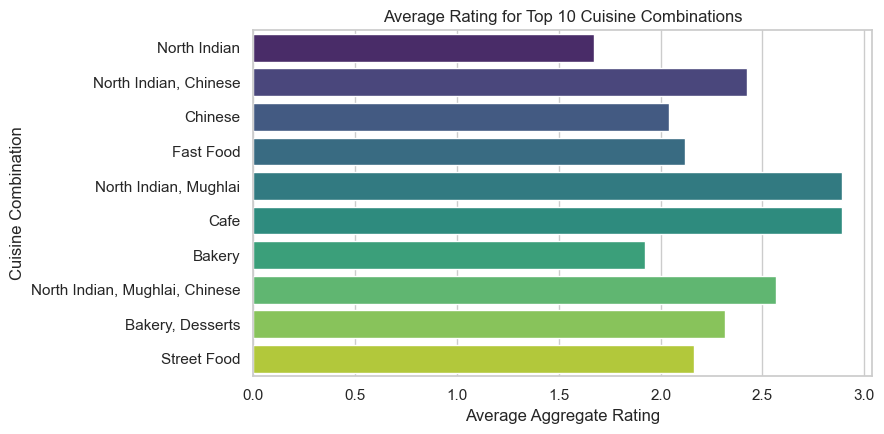

In [3]:
# Task 2: Cuisine Combinations and Their Average Ratings
top_10_combos = df['Cuisines'].value_counts().head(10)

combo_ratings = df[df['Cuisines'].isin(top_10_combos.index)].groupby('Cuisines')['Aggregate rating'].agg(
    Outlet_Count='count',
    Average_Rating='mean'
).loc[top_10_combos.index]

print("Top 10 Most Common Cuisine Combinations & Their Average Ratings:")
print(combo_ratings.sort_values(by='Average_Rating', ascending=False).round(2))

# Visualization (uses hue to avoid Seaborn FutureWarning)
plt.figure(figsize=(9, 4.5))
sns.barplot(
    x=combo_ratings['Average_Rating'], 
    y=combo_ratings.index, 
    hue=combo_ratings.index, 
    palette='viridis', 
    legend=False
)
plt.title('Average Rating for Top 10 Cuisine Combinations')
plt.xlabel('Average Aggregate Rating')
plt.ylabel('Cuisine Combination')
plt.show()

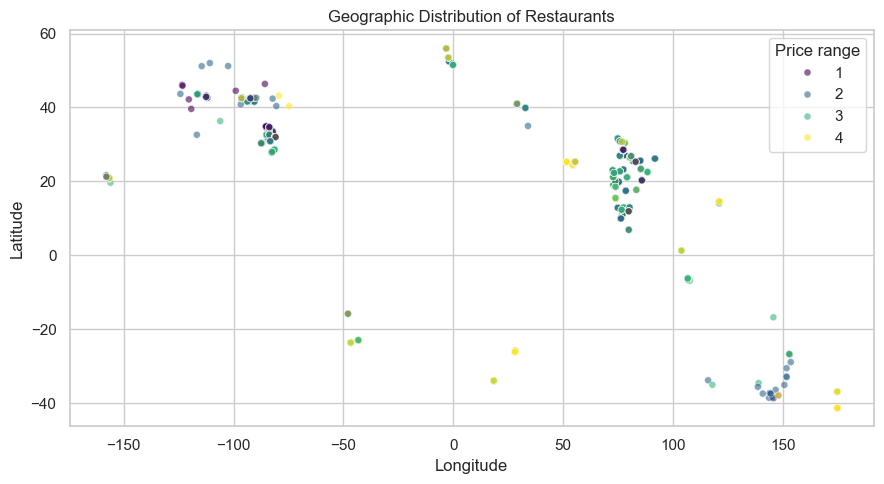

Top 5 Geographic Restaurant Density Clusters:
City
New Delhi    5240
Gurgaon      1070
Noida         986
Faridabad     229
Ghaziabad      25
Name: count, dtype: int64


In [4]:
# Task 3: Geographic Distribution & Clustering
# Filter out records with invalid (0.0, 0.0) coordinates
valid_coords = df[(df['Longitude'] != 0) & (df['Latitude'] != 0)]

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=valid_coords, 
    x='Longitude', 
    y='Latitude', 
    hue='Price range', 
    palette='viridis', 
    alpha=0.6, 
    s=25
)
plt.title('Geographic Distribution of Restaurants')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

# Major city clusters in the dataset
print("Top 5 Geographic Restaurant Density Clusters:")
print(valid_coords['City'].value_counts().head(5))

Total Restaurant Chains Identified: 734

Top 10 Chains Summary:
                  Outlets  Average_Rating  Total_Votes
Restaurant Name                                       
Cafe Coffee Day        83            2.42         2428
Domino's Pizza         79            2.74         6643
Subway                 63            2.91         6124
Green Chick Chop       51            2.67          964
McDonald's             48            3.34         5291
Keventers              34            2.87         1263
Pizza Hut              30            3.32         4961
Giani                  29            2.69          854
Baskin Robbins         28            1.86          428
Barbeque Nation        26            4.35        28142


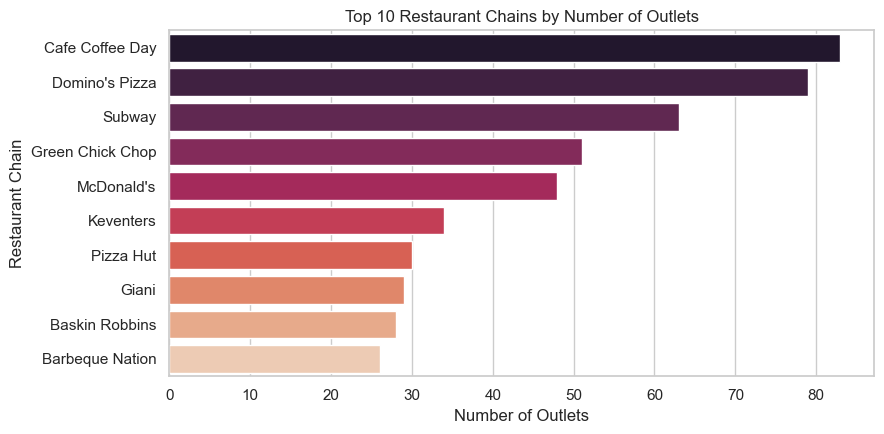

In [5]:
# Task 4: Restaurant Chains Analysis
# Identify chains: names appearing more than once
name_counts = df['Restaurant Name'].value_counts()
chains = name_counts[name_counts > 1]
print(f"Total Restaurant Chains Identified: {len(chains)}")

# Aggregate metrics for the top 10 chains by outlet count
top_chains_summary = df[df['Restaurant Name'].isin(chains.head(10).index)].groupby('Restaurant Name').agg(
    Outlets=('Restaurant ID', 'count'),
    Average_Rating=('Aggregate rating', 'mean'),
    Total_Votes=('Votes', 'sum')
).sort_values(by='Outlets', ascending=False)

print("\nTop 10 Chains Summary:")
print(top_chains_summary.round(2))

# Visualization
plt.figure(figsize=(9, 4.5))
sns.barplot(
    x=top_chains_summary['Outlets'], 
    y=top_chains_summary.index, 
    hue=top_chains_summary.index, 
    palette='rocket', 
    legend=False
)
plt.title('Top 10 Restaurant Chains by Number of Outlets')
plt.xlabel('Number of Outlets')
plt.ylabel('Restaurant Chain')
plt.show()